In [2]:
import numpy as np
from sklearn.model_selection import train_test_split # Divisão de treino e teste
from sklearn.metrics import accuracy_score # Calcula a acurácia dos resultados
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

In [3]:
import pandas as pd

# Lê o arquivo
dataset = pd.read_parquet("base_final_com_vetores.parquet")

# Mostra as primeiras linhas com os textos e os vetores
dataset.head(5)

,text,url,text_news,source_name,title,categories,rating,label,vetores
0,A médica Helen Brandão enviou 34 estudos para ...,https://projetocomprova.com.br/publica%C3%A7%C...,"Procurada pelo Comprova, médica enviou 34 estu...",COMPROVA,Médica cita estudos não conclusivos para suger...,['Pandemia'],['enganoso'],fato,"[-0.034125887, -0.006687274, -0.0022898377, -0..."
1,Parte dos trechos das gravações utilizadas no ...,https://projetocomprova.com.br/publica%C3%A7%C...,Parte dos trechos das gravações utilizadas no ...,COMPROVA,Post mostra imagens de outras estradas para af...,['Políticas públicas'],['falso'],fato,"[-0.0522128, -0.027455853, -0.01047504, 0.0076..."
2,A Ancine aprovou em 2019 a captação de 530 mil...,https://projetocomprova.com.br/publica%C3%A7%C...,Ancine aprovou em 2019 a captação de 530 mil r...,COMPROVA,Publicações enganam ao associar Bolsonaro à ap...,['Políticas públicas'],['enganoso'],fato,"[0.0057873838, 0.006586142, 0.027413025, 0.078..."
3,A imagem que circula nas redes sociais é de um...,https://projetocomprova.com.br/publica%C3%A7%C...,Imagem que circula nas redes sociais é de um t...,COMPROVA,"Imagem de Doria tomando vacina é de março, ant...",['Pandemia'],['enganoso'],fato,"[-0.017145151, 0.018176142, -0.0030616773, -0...."
4,Tanto a Organização Mundial da Saúde (OMS) qua...,https://projetocomprova.com.br/publica%C3%A7%C...,Ao contrário do que afirma uma médica em vídeo...,COMPROVA,Médica usa informações falsas em vídeo para fa...,['Pandemia'],['falso'],fato,"[0.0020873586, 0.030779682, -0.05216051, -0.02..."


In [4]:
# print(dataset['text'].iloc[1])
# print("\n" + "-"*50 + "\n")

# print(dataset['text_news'].iloc[1])
# print("\n" + "-"*50 + "\n")

# print(dataset['vetores'].iloc[1])
# print("\n" + "-"*50 + "\n")



# Definindo X (vetores das embeddings) e y (coluna label)

# Separação em treino (70%) e teste (30%)

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split

# ==========================================
# ETAPA 1: DEFINIÇÃO DE X e y
# ==========================================

# X é a matriz de características (os embeddings)
# np.stack() é usado pois o scikit-learn precisa de uma matriz 2D geométrica perfeita, e não de uma simples coluna do Pandas.
X = np.stack(dataset['vetores'].values)

# y é o gabarito
# Nesse caso, é o 'label'
y = dataset['label'].values

# ==========================================
# ETAPA 2: DIVISÃO TREINO E TESTE
# ==========================================

# Função train_test_split. 
# 4 parâmetros (o X, o y, o tamanho do teste, e uma semente aleatória)
# test_size=0.3 significa separar 30% para a prova final.
# random_state=42 serve para travar a aleatoriedade. Ao rodar 10 vezes, ele vai separar as exatas mesmas notícias.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Total de notícias para estudar (Treino): {len(X_train)}")
print(f"Total de notícias para a prova (Teste): {len(X_test)}")

Total de notícias para estudar (Treino): 16216
Total de notícias para a prova (Teste): 6951


# Rodando os algoritmos de Machine Learning

In [6]:
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

print("Iniciando a bateria de testes...\n")

# ==========================================
# 1. REGRESSÃO LOGÍSTICA
# ==========================================
print("Treinando Regressão Logística...")
modelo_lr = LogisticRegression(max_iter=1000) 
modelo_lr.fit(X_train, y_train)

pred_lr = modelo_lr.predict(X_test)
nota_lr = accuracy_score(y_test, pred_lr)


# ==========================================
# 2. SVM (Máquina de Vetores de Suporte)
# ==========================================
print("Treinando SVM...")
modelo_svm = SVC(kernel='linear', random_state=42)
modelo_svm.fit(X_train, y_train)

pred_svm = modelo_svm.predict(X_test)
nota_svm = accuracy_score(y_test, pred_svm)

# ==========================================
# 3. RANDOM FOREST (Floresta Aleatória)
# ==========================================
print("Treinando Random Forest...")
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)

pred_rf = modelo_rf.predict(X_test)
nota_rf = accuracy_score(y_test, pred_rf)


# ==========================================
# 4. MLP (Rede Neural)
# ==========================================
print("Treinando MLP (Rede Neural)...")
modelo_mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
modelo_mlp.fit(X_train, y_train)

pred_mlp = modelo_mlp.predict(X_test)
nota_mlp = accuracy_score(y_test, pred_mlp)


# ==========================================
# RELATÓRIO FINAL
# ==========================================
print("\n" + "="*45)
print("BOLETIM DE NOTAS (ACURÁCIA)")
print("="*45)

# Multiplicando por 100 para transformar em porcentagem
print(f"#1 Regressão Logística : {nota_lr * 100:.2f}%")
print(f"#2 SVM                 : {nota_svm * 100:.2f}%")
print(f"#3 Random Forest       : {nota_rf * 100:.2f}%")
print(f"#4 Rede Neural (MLP)   : {nota_mlp * 100:.2f}%")
print("="*45)

Iniciando a bateria de testes...

Treinando Regressão Logística...
Treinando SVM...
Treinando Random Forest...
Treinando MLP (Rede Neural)...

BOLETIM DE NOTAS (ACURÁCIA)
#1 Regressão Logística : 97.91%
#2 SVM                 : 98.53%
#3 Random Forest       : 94.99%
#4 Rede Neural (MLP)   : 98.48%


Comprimindo 1024 dimensões matematicas em 2D... (Isso pode levar alguns segundos)


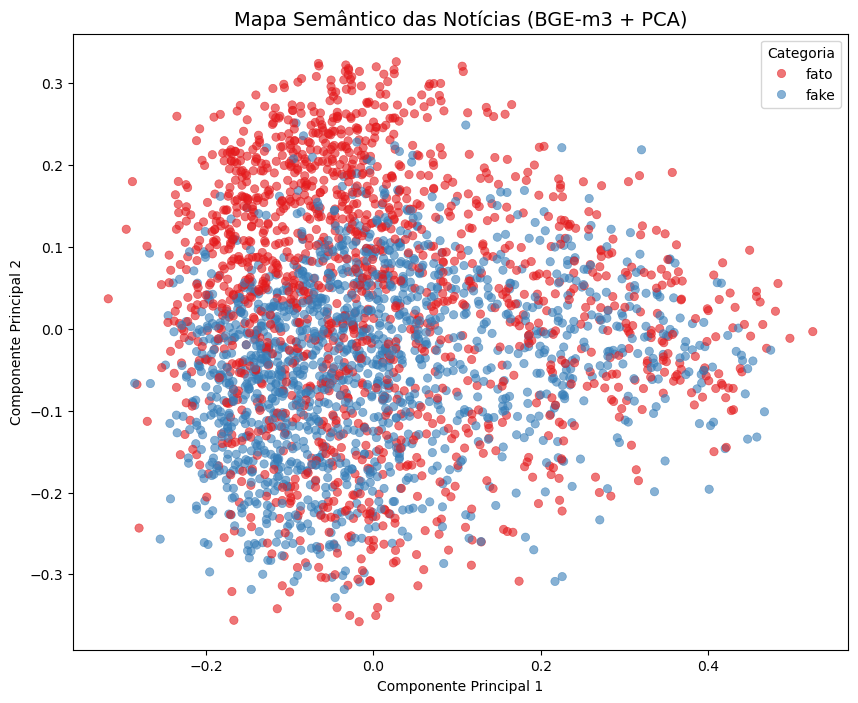

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA

print("Comprimindo 1024 dimensões matematicas em 2D... (Isso pode levar alguns segundos)")

# Utilizando uma amostra do Teste para o gráfico renderizar sem travar o Colab
amostra_X = X_test[:3000]
amostra_y = y_test[:3000]

# Instanciação do PCA usando apenas 2 componentes (Eixos X e Y)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(amostra_X)

# Criando uma tabela temporária só para o gráfico
df_grafico = pd.DataFrame(data=X_pca, columns=['Eixo X', 'Eixo Y'])
df_grafico['Categoria'] = amostra_y

# Desenhando o gráfico de dispersão (Scatter Plot)
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Eixo X', 
    y='Eixo Y',
    hue='Categoria',
    data=df_grafico,
    palette='Set1', # Paleta de cores de alto contraste
    alpha=0.6,      # Deixa os pontos levemente transparentes para ver onde há sobreposição
    edgecolor=None
)

plt.title('Mapa Semântico das Notícias (BGE-m3 + PCA)', fontsize=14)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.show()

In [9]:
from sklearn.metrics import classification_report

print("="*60)
print("RELATÓRIO DETALHADO - 1. REGRESSÃO LOGÍSTICA")
print("="*60)
print(classification_report(y_test, pred_lr, digits=4))


print("\n" + "="*60)
print("RELATÓRIO DETALHADO - 2. SVM (MÁQUINA DE VETORES)")
print("="*60)
print(classification_report(y_test, pred_svm, digits=4))


print("\n" + "="*60)
print("RELATÓRIO DETALHADO - 3. RANDOM FOREST")
print("="*60)
print(classification_report(y_test, pred_rf, digits=4))


print("\n" + "="*60)
print("RELATÓRIO DETALHADO - 4. MLP (REDE NEURAL)")
print("="*60)
print(classification_report(y_test, pred_mlp, digits=4))

RELATÓRIO DETALHADO - 1. REGRESSÃO LOGÍSTICA
              precision    recall  f1-score   support

        fake     0.9882    0.9696    0.9788      3452
        fato     0.9705    0.9886    0.9795      3499

    accuracy                         0.9791      6951
   macro avg     0.9794    0.9791    0.9791      6951
weighted avg     0.9793    0.9791    0.9791      6951


RELATÓRIO DETALHADO - 2. SVM (MÁQUINA DE VETORES)
              precision    recall  f1-score   support

        fake     0.9912    0.9791    0.9851      3452
        fato     0.9797    0.9914    0.9855      3499

    accuracy                         0.9853      6951
   macro avg     0.9854    0.9853    0.9853      6951
weighted avg     0.9854    0.9853    0.9853      6951


RELATÓRIO DETALHADO - 3. RANDOM FOREST
              precision    recall  f1-score   support

        fake     0.9611    0.9371    0.9490      3452
        fato     0.9395    0.9626    0.9509      3499

    accuracy                         0.9499   

Comprimindo 1024 dimensões matematicas em 2D... (Isso pode levar alguns segundos)


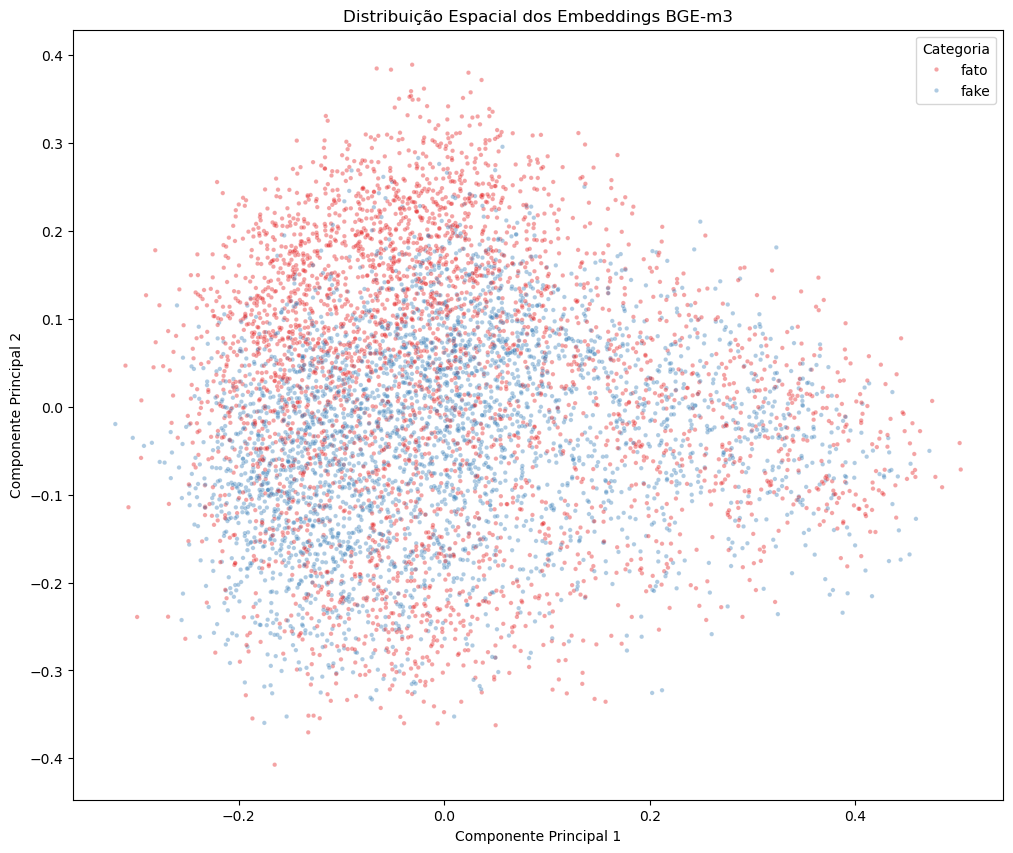

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA

print("Comprimindo 1024 dimensões matematicas em 2D... (Isso pode levar alguns segundos)")

# Utilizando uma amostra do Teste para o gráfico renderizar sem travar
amostra_X = X_test
amostra_y = y_test

# Instanciação do PCA usando apenas 2 componentes (Eixos X e Y)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(amostra_X)

df_pca = pd.DataFrame({
    'Eixo X': X_pca[:, 0],
    'Eixo Y': X_pca[:, 1],
    'Categoria': amostra_y # Substitua amostra_y pelo nome real da sua variável de rótulos
})


# Criando uma tabela temporária só para o gráfico
df_grafico = pd.DataFrame(data=X_pca, columns=['Eixo X', 'Eixo Y'])
df_grafico['Categoria'] = amostra_y

# Desenhando o gráfico de dispersão (Scatter Plot)
plt.figure(figsize=(12, 10)) # Aumentamos um pouco o tamanho da figura para acomodar melhor os dados
sns.scatterplot(
    data=df_pca,
    x='Eixo X', 
    y='Eixo Y',
    hue='Categoria',
    palette='Set1', # Paleta de cores de alto contraste
    alpha=0.4,      # Deixa os pontos levemente transparentes para ver onde há sobreposição
    # edgecolor=None,
    s=10
)

plt.title('Distribuição Espacial dos Embeddings BGE-m3')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')

# Exibe o gráfico
plt.show()